# 05 · A/B test design, simulation & ROI

<sub>Telco churn analysis &nbsp;|&nbsp; 01 Framing · 02 Cleaning & EDA · 03 Hypothesis tests · 04 Modelling · **05 A/B test & ROI**</sub>

**Goal:** decide whether a **20 % discount for 3 months** to high-risk month-to-month customers is worth it, and how to prove it.

> **Key findings**
>
> - Detecting 26 % → 21 % takes **1,126 customers per arm**; the real segment (62 % baseline) needs **1,513 per arm**, so two quarterly waves.
> - The offer breaks even at a **4.3-pt** churn reduction (2.4–7.5 pts depending on how long saved customers stay).
> - A simulated test (true effect 5 pts) observes 4.3 pts [1.3, 7.3], which straddles break-even: **inconclusive, don't roll out yet**.
> - Recommendation: pre-register the decision rule, power the test for the *break-even* effect, and test a contract-upgrade incentive alongside.

In [1]:
import sys, warnings; from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from churn import config as C, style, charts
style.setup()

In [2]:
from churn import ab_testing as ex

scored = pd.read_pickle(C.SCORED_PATH)   # out-of-fold calibrated churn probabilities
RISK_THRESHOLD, DISCOUNT, MONTHS, TRUE_EFFECT, WAVES = 0.40, 0.20, 3, 0.05, 2

## 1 · Target segment

In [3]:
m2m = scored[scored.contract == "Month-to-month"]
segment = m2m[m2m.churn_prob >= RISK_THRESHOLD]
p0, mrr = segment.churn.mean(), segment.monthly_charges.mean()
style.card({"Segment size": f"{len(segment):,} customers ({len(segment) / len(scored):.0%} of base)",
          "Share of all churners": f"{segment.churn.sum() / scored.churn.sum():.0%}",
          "Observed vs predicted churn": f"{p0:.1%} vs {segment.churn_prob.mean():.1%}",
          "Average monthly charge": f"${mrr:.2f}"}, caption="High-risk month-to-month customers")

Segment size,"2,039 customers (29% of base)"
Share of all churners,68%
Observed vs predicted churn,61.9% vs 62.3%
Average monthly charge,$77.92


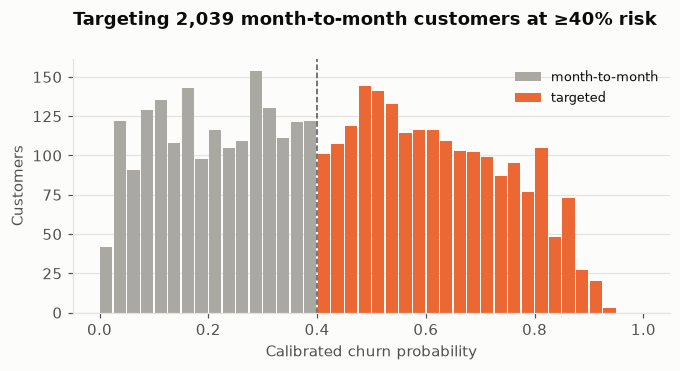

In [4]:
charts.segment_hist(m2m, segment, RISK_THRESHOLD);

> Predicted churn matches observed churn, which is calibration paying off: the baseline for power and ROI is trustworthy.

## 2 · Power analysis

Two-sided two-proportion z-test · α = 0.05 · power = 80 % · 1 : 1 allocation.

In [5]:
n_brief, n_seg = ex.n_per_arm(0.26, 0.21), ex.n_per_arm(p0, p0 - 0.05)
mde = ex.min_detectable_effect(p0, len(segment) // 2)
style.card({"26% → 21% (as posed)": f"{n_brief:,} per arm · {2 * n_brief:,} total",
          f"{p0:.0%} → {p0 - .05:.0%} (real segment)": f"{n_seg:,} per arm · {2 * n_seg:,} total",
          "Available in one wave": f"{len(segment) // 2:,} per arm",
          "Detectable effect in one wave": f"{mde * 100:.1f} pts"}, caption="Sample size for a 5-pt drop")

26% → 21% (as posed),"1,126 per arm · 2,252 total"
62% → 57% (real segment),"1,513 per arm · 3,026 total"
Available in one wave,"1,019 per arm"
Detectable effect in one wave,6.1 pts


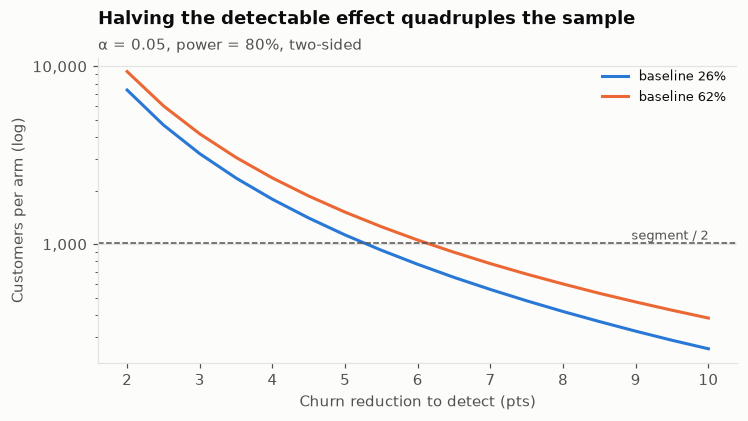

In [6]:
effects = np.arange(2, 10.5, 0.5)
curve = pd.DataFrame({"baseline 26%": [ex.n_per_arm(.26, .26 - e / 100) for e in effects],
                      f"baseline {p0:.0%}": [ex.n_per_arm(p0, p0 - e / 100) for e in effects]}, index=effects)
charts.power_curve(curve, len(segment) // 2);

> **Design trap:** "26 % → 21 %" uses the *company* baseline, but the offer targets a 62 % segment. Variance p(1−p) is higher there (0.24 vs 0.19), so the same 5-pt drop needs **~⅓ more** customers, more than one wave provides. Hence two quarterly waves.

## 3 · Simulated experiment

Randomise 50/50 · control churns with its calibrated probability · treatment probability scaled so the average drops **5 pts** · two waves.

In [7]:
rng = np.random.default_rng(2026)
probs = rng.choice(segment.churn_prob.to_numpy(), size=WAVES * len(segment))
res = ex.simulate_experiment(probs, TRUE_EFFECT, rng)
style.card({"Arms": f"{res['n_control']:,} control · {res['n_treatment']:,} treatment",
          "Churn": f"{res['churn_control']:.1%} → {res['churn_treatment']:.1%}",
          "Observed reduction": f"{res['diff'] * 100:.1f} pts [{res['ci_low'] * 100:.1f}, {res['ci_high'] * 100:.1f}]",
          "z · p-value": f"{res['z']:.2f} · {res['p_value']:.4f}"}, caption="One simulated experiment")

Arms,"2,039 control · 2,039 treatment"
Churn,61.6% → 57.4%
Observed reduction,"4.3 pts [1.3, 7.3]"
z · p-value,2.78 · 0.0055


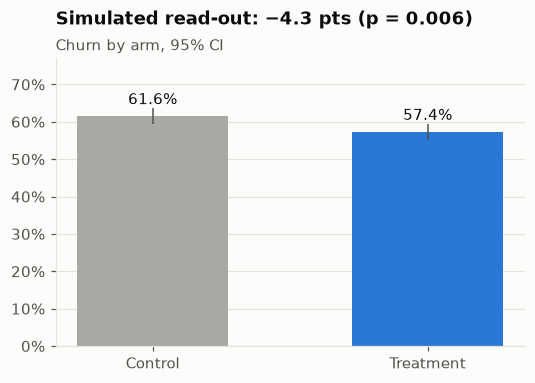

In [8]:
charts.arm_bars(res);

Empirical power: 90.1% · false-positive rate under no effect: 4.8%


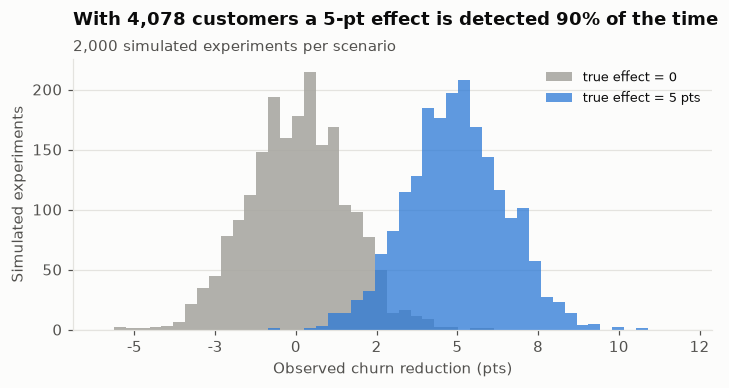

In [9]:
mc_eff = ex.monte_carlo(probs, TRUE_EFFECT, n_sims=2000, seed=1)
mc_null = ex.monte_carlo(probs, 0.0, n_sims=2000, seed=2)
print(f"Empirical power: {mc_eff.significant.mean():.1%} · false-positive rate under no effect: {mc_null.significant.mean():.1%}")
charts.monte_carlo(mc_null, mc_eff, len(probs));

## 4 · ROI and break-even

Per treated customer: **cost** = 20 % × MRR × 3 months × P(stay). The discount also goes to people who'd have stayed anyway, the *dead-weight* cost. **Benefit** = churn reduction *d* × MRR × *L* (expected remaining months of a saved customer).

$$d^* = \frac{0.6\,(1-p_0)}{L-0.6}\quad\text{(the monthly charge cancels out)}$$

*L* is the most uncertain input, so we bracket it:

In [10]:
L = {"conservative": float(ex.expected_remaining_months(p0)),               # stays at segment risk
     "base": float(ex.expected_remaining_months(m2m.churn.mean())),        # like an average M2M customer
     "optimistic": float(ex.expected_remaining_months(scored.churn.mean()))}  # like an average customer
be = pd.DataFrame({f"{d:.0%} off": {k: ex.break_even_effect(p0, l, d) * 100 for k, l in L.items()}
                   for d in (0.10, 0.20, 0.30)})
be.insert(0, "L (months)", pd.Series(L))
style.table(be, fmt="{:.1f}", caption="Break-even churn reduction (pts)", highlight=["base"])

,L (months),10% off,20% off,30% off
conservative,3.6,3.4,7.5,12.5
base,5.9,2.0,4.3,6.8
optimistic,10.2,1.1,2.4,3.7


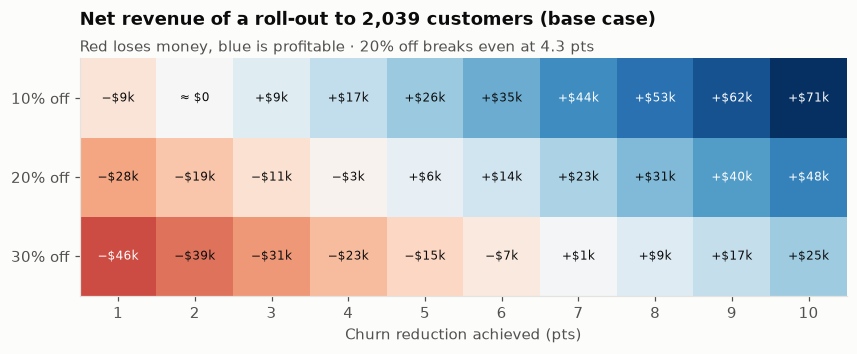

In [11]:
grid = ex.sensitivity_grid(p0, mrr, L["base"], n_customers=len(segment))
charts.roi_heatmap(grid.pivot(index="discount", columns="effect_pts", values="net_total"),
                  f"Net revenue of a roll-out to {len(segment):,} customers (base case)",
                  f"Red loses money, blue is profitable · 20% off breaks even at {ex.break_even_effect(p0, L['base'], .2) * 100:.1f} pts");

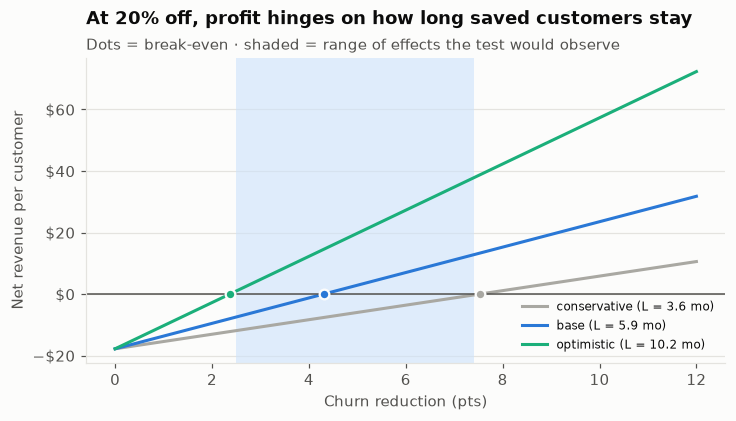

In [12]:
ds = np.linspace(0, 0.12, 121)
curves = {f"{k} (L = {l:.1f} mo)": (ds * 100, [ex.roi_per_customer(p0, d, mrr, l, DISCOUNT, MONTHS)["net"] for d in ds])
          for k, l in L.items()}
breakevens = {f"{k} (L = {l:.1f} mo)": ex.break_even_effect(p0, l, DISCOUNT) * 100 for k, l in L.items()}
charts.breakeven_lines(curves, breakevens, band=(mc_eff["diff"].quantile(.05) * 100, mc_eff["diff"].quantile(.95) * 100));

## 5 · Decision

In [13]:
d_star = ex.break_even_effect(p0, L["base"], DISCOUNT)
rows = {label: ex.roi_per_customer(p0, d, mrr, L["base"], DISCOUNT, MONTHS)
        for label, d in [("CI low", res["ci_low"]), ("point estimate", res["diff"]), ("CI high", res["ci_high"])]}
decision = pd.DataFrame({"effect (pts)": [d * 100 for d in (res["ci_low"], res["diff"], res["ci_high"])],
                         "net for segment": [r["net"] * len(segment) for r in rows.values()],
                         "ROI": [r["roi"] for r in rows.values()]}, index=list(rows))
verdict = "ROLL OUT" if res["ci_low"] > d_star else "DON'T ROLL OUT" if res["ci_high"] < d_star else "INCONCLUSIVE"
style.table(decision, fmt={"effect (pts)": "{:.1f}", "net for segment": lambda v: style.money(v), "ROI": "{:+.0%}"},
          caption=f"Rule: roll out only if CI low > break-even ({d_star * 100:.1f} pts) → {verdict}")

,effect (pts),net for segment,ROI
CI low,1.3,"−$25,721",-69%
point estimate,4.3,−$343,-1%
CI high,7.3,"$24,942",+58%


## Recommendation

1. **Run the test; don't roll out blind.** The 20 %/3-month offer breaks even near the effect we hope for, so the decision depends on the experiment.
2. **Power for the break-even effect, not "any effect".** A significant 2-pt drop still loses money.
3. **Pre-register the rule:** roll out if the lower 95 % bound exceeds break-even; iterate if the CI straddles it.
4. **Test cheaper levers alongside:** a discount *conditional on* moving to a 1-year contract (contract is the strongest driver), or a free security/tech-support bundle.
5. **Measure L directly:** follow both arms for 2–3 quarters after the discount ends. It is the biggest source of ROI uncertainty.